# Overview of Mislocalized Variants

In [1]:
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
from kneed import KneeLocator
import umap
import pandas as pd
from utils import inverse_normal_transform
# from adjustText import adjust_text
import igraph as ig
import leidenalg

sns.set_theme(style='white')

## 1. Loading Data

In [2]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")
feat_adj_df = pl.read_csv("../../3_outputs/feat_importance_adj_gt1e-3_all_alleles.csv")

In [ ]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("img_pheno_hit"),
)
imaging_summary_clinvar_misloc_hits = imaging_summary_clinvar.filter(
    pl.col("img_misloc_hit"),
)
pheno_alleles = imaging_summary_clinvar_hits["gene_variant"].to_list()
print("Imaging phenotype alleles:", len(pheno_alleles))
misloc_alleles = imaging_summary_clinvar_misloc_hits["gene_variant"].to_list()
print("Protein mislocalized alleles:", len(misloc_alleles))

## Protein abundance change
imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
)
prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_variant"].to_list()


# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()
imaging_summary_clinvar_hits

Imaging phenotype alleles: 140
Protein mislocalized alleles: 112


Gene,gene_variant,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,img_pheno_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,f64,bool,bool,bool
"""PMP22""","""PMP22_Leu16Pro""",2.879899,0.028061,-7.896223,0.000219,0.000773,0.000773,"""2024_01_Batch_7-8""",true,true,false,false,false,false,false,false,false,false,false,false,0.972047,0.978439,0.527243,0.689174,0.720481,0.593552,0.678036,0.737426,0.740387,0.617828,0.990193,0.986164,0.509068,0.703537,0.637962,0.436657,…,null,null,-42.5,null,null,null,null,null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,"""Helical""",null,null,98.0,14.634146,""">90""","""10-90""","""118220""","""autosomal dominant""","""OMIM""","""Genetic otorhinolaryngologic d…",3,"""CHARCOT-MARIE-TOOTH DISEASE, D…",false,0.978439,0.972047,true,true,false
"""FXN""","""FXN_Met1Ile""",3.750084,0.007167,-4.062661,0.004793,0.009382,0.009382,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.989749,0.996017,0.789821,0.868702,0.745553,0.809808,0.771908,0.687244,0.870907,0.746232,0.997118,0.989749,0.847707,0.803862,0.866496,0.83341,…,null,null,80.4,null,null,null,null,null,"""C (loop/coil)""","""C (loop/coil)""",null,null,null,null,null,null,null,"""Mitochondrion""",null,null,null,45.27,100.0,"""$\leqslant$50""","""$\geqslant$90""","""229300""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""FRIEDREICH ATAXIA""",false,0.996017,0.989749,true,true,true
"""SFTPC""","""SFTPC_Ile73Thr""",-1.5761,0.166074,18.02773,0.000002,0.000028,0.000028,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.994773,0.994331,0.825766,0.822123,0.807482,0.850061,0.968498,0.816135,0.952122,0.936955,0.994104,0.994773,0.731623,0.798829,0.692124,0.714576,…,null,"""Propeptide""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,50.61,82.84023,"""50-70""","""10-90""","""610913""","""autosomal dominant""","""OMIM""","""Rare genetic respiratory disea…",1,"""SURFACTANT METABOLISM DYSFUNCT…",false,0.994331,0.994773,true,true,true
"""ML

## 2. Imaging Phenotype Variants

In [5]:
FEATURE_IMPORTANCE_THRES = 0.01

In [ ]:
# TOP_NUM_FEAT_MISLOC_VAR = 5
# # Get top 10 for each variant with feature names
# top_feat_misloc_alleles = []
# for col in misloc_alleles:
#     top_feats = feat_df.filter(
#         pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
#     ).select(["cp_feature", col])
#     # print(top_feats.sort(col))
#     top_feat_misloc_alleles.append(top_feats)
    
# # Start with all features and left join each variant's top 10
# result_df = feat_df.select("cp_feature").unique().sort("cp_feature")
# for i, col in enumerate(misloc_alleles):
#     result_df = result_df.join(top_feat_misloc_alleles[i], on="cp_feature", how="left")

# misloc_var_top10_feat_df = result_df.select(
#     ["cp_feature"] + pheno_alleles
# ).filter(
#     ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
# )
# get_top_n_feats_misloc_alleles = misloc_var_top10_feat_df["cp_feature"].to_list()
# len(get_top_n_feats_misloc_alleles)

In [12]:
pheno_var_sig_feat_df = feat_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(pheno_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_pheno_alleles = pheno_var_sig_feat_df["cp_feature"].to_list()

In [9]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_pheno_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_vars_feat_df = pl.concat(
        [norm_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 44/44 [00:10<00:00,  4.25it/s]


__Robust Feature Preprocessing__

To mitigate the impact of extreme outliers on downstream distance-based analyses (e.g., hierarchical clustering, PCA) while preserving the linear directionality and magnitude of biological perturbations, we applied a Winsorization (clipping) procedure to the feature Z-scores. Z-scores were thresholded at a minimum of -5 and a maximum of +5. This step affected less than 0.1% of the data points, predominantly capping extreme artifacts (e.g., $|Z| > 20$) that would otherwise disproportionately skew Euclidean distance calculations. Unlike rank-based normalizations, this approach retains the relative scale of significant feature variations, ensuring that strong biological signals remain quantitatively distinct from subtle fluctuations.

In [23]:
# Standardize the features before PCA
# var_zscore_feat_gfp_filtered_int_df = inverse_normal_transform(norm_vars_feat_df)
var_zscore_feat_gfp_filtered_int_df = norm_vars_feat_df.to_pandas().set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping)
# We clip values at -5 (lower) and +5 (upper)
var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

## Append important medadata to data frame
cols = [
    "gene_variant",
    "Metadata_Bio_Batch",
    "img_pheno_score",
    "img_misloc_score",
    "img_pheno_hit",
    "img_misloc_hit",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
]
var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(cols).rename(
        {k: f"Metadata_{k}" for k in cols if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

In [24]:
df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
df.shape

(140, 52)

In [28]:
# # Perform PCA
# pca = PCA()
# pca_result = pca.fit_transform(df)

# # Calculate variances
# explained_variance_ratio = pca.explained_variance_ratio_
# cumulative_variance = np.cumsum(explained_variance_ratio)

# # Find elbow point using KneeLocator
# knee_locator = KneeLocator(
#     range(1, len(explained_variance_ratio)+1),
#     explained_variance_ratio,
#     curve='convex',
#     direction='decreasing'
# )
# optimal_components = knee_locator.knee

# # Plot results
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# # Scree plot
# n_show = min(15, len(explained_variance_ratio))
# ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
# ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
# ax1.set_xlabel('Principal Component')
# ax1.set_ylabel('Explained Variance Ratio')
# ax1.set_title('Scree Plot')
# ax1.set_xticks(range(1, n_show + 1))
# ax1.legend()
# ax1.grid(True, alpha=0.3)

# # Cumulative variance plot
# ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
# ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
# ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
# ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
# ax2.set_xlabel('Principal Component')
# ax2.set_ylabel('Cumulative Explained Variance')
# ax2.set_title('Cumulative Explained Variance')
# ax2.set_xticks(range(1, n_show + 1))
# ax2.legend()
# ax2.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

# # Results
# print(f"Optimal components: {optimal_components}")
# print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [25]:
metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]

# ----------------------------------------------------------------------
# 2. Robust PCA
# ----------------------------------------------------------------------
# Dynamic component selection: Keep 90% of variance
pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)
n_pcs = data_pca.shape[1]
print(f"PCA retained {n_pcs} components explaining 90% variance.")

# Create PCA DataFrame dynamically
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]
pca_df = pd.DataFrame(data_pca, columns=pca_cols)
# Safely attach metadata using index alignment
pca_df = pd.concat([df_meta[metadata_cols].reset_index(drop=True), pca_df], axis=1)

# ----------------------------------------------------------------------
# 3. Robust Graph Construction (Euclidean + Higher K)
# ----------------------------------------------------------------------
k = 10  # Increased from 5 to 15 for better cluster stability
# CRITICAL CHANGE: Use 'euclidean' for PCA data, not 'cosine'
nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean")
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# ----------------------------------------------------------------------
# 4. UMAP (Aligned with Graph)
# ----------------------------------------------------------------------
umap_model = umap.UMAP(
    n_neighbors=k,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    metric="euclidean",  # Match the KNN metric
    init="spectral"      # More stable initialization
)

# Use precomputed KNN for consistency
umap_result = umap_model.fit_transform(data_pca, knn_indices=indices, knn_dists=distances)

umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])

# ----------------------------------------------------------------------
# 5. Leiden Clustering
# ----------------------------------------------------------------------
# Build graph from KNN indices
edges = []
# i is the sample index, neighbors are in indices[i]
for i in range(indices.shape[0]):
    # Note: indices[i, 0] is usually the point itself (distance 0), so we skip it
    for neighbor in indices[i, 1:]: 
        edges.append((i, neighbor))

g = ig.Graph(edges=edges, directed=False)

# Tune resolution: Start at 0.5 - 1.0. Lower = fewer, larger clusters.
resolution = 0.8 
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    weights=None, 
    resolution_parameter=resolution,
    seed=42
)
cluster_labels = np.array(partition.membership) + 1 # 1-based indexing

# ----------------------------------------------------------------------
# 6. Compile Results
# ----------------------------------------------------------------------
dr_res_df = pd.concat([pca_df, umap_df], axis=1)
dr_res_df["Metadata_cluster"] = cluster_labels
dr_res_df.index = df.index  # Preserve original index

# print("Clustering complete. Columns:", dr_res_df.columns)

PCA retained 8 components explaining 90% variance.


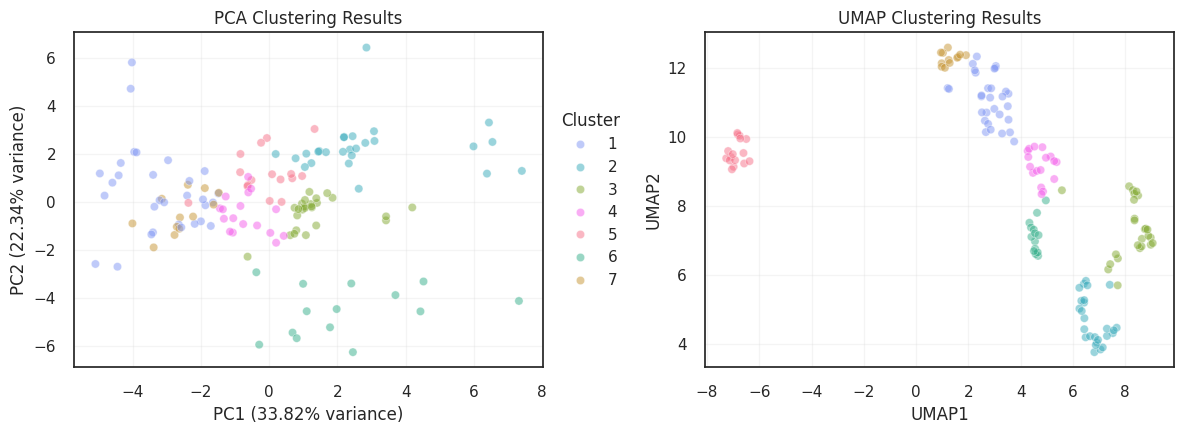

In [30]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=1)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5,
    legend=False
)
# Add text labels for high-scoring points in PCA
high_score_mask = dr_res_df['Metadata_img_pheno_hit']==True

# ax[1].get_legend().remove()

texts_pca = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_pca.append(
#       ax[0].text(
#        dr_res_df.loc[idx, 'PC1'],
#        dr_res_df.loc[idx, 'PC2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_pca, ax=ax[0], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# Add text labels for high-scoring points in UMAP
texts_umap = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_umap.append(ax[1].text(
#        dr_res_df.loc[idx, 'UMAP1'],
#        dr_res_df.loc[idx, 'UMAP2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_umap, ax=ax[1], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

In [42]:
# # Plot UMAP
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# sns.scatterplot(data=pca_df.sort_values(by="Metadata_Bio_Batch"), alpha=.5,
#                 x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", s=40, ax=axes[0]) ## hue=variant_type, 
# # texts = []
# # for i, label in enumerate(group2_labels):
# #     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
# #         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
# #                      fontsize=6, fontweight='bold', color='black'))
# # adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
# axes[0].set_title("PCA Plot")
# axes[0].set_xlabel("PC1")
# axes[0].set_ylabel("PC2")
# axes[0].legend(title="Metadata_Bio_Batch")

# # umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
# # umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# # Plot UMAP
# sns.scatterplot(data=dr_res_df.sort_values(by="Metadata_Bio_Batch"), x="UMAP1", y="UMAP2", 
# hue="Metadata_Bio_Batch", palette="Set2", alpha=.5, s=30, ax=axes[1]) ## hue=variant_type, 
# # texts = []
# # for i, label in enumerate(group2_labels):
# #     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
# #         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
# #                      fontsize=6, fontweight='bold', color='black'))
# # adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
# axes[1].set_title("UMAP Plot")
# axes[1].set_xlabel("UMAP1")
# axes[1].set_ylabel("UMAP2")
# axes[1].legend(title="Metadata_Bio_Batch")
# plt.tight_layout()
# plt.show()

In [33]:
# Get cluster order from UMAP clustering
cluster_order = dr_res_df.sort_values('Metadata_cluster')['Metadata_cluster'].unique()

# Create cluster color mapping
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
cluster_colors = sns.color_palette("husl", n_clusters)
cluster_color_map = {cluster: cluster_colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

# Create ordered list based on clusters, then by score within clusters
ordered_variants = []
cluster_labels = []

for cluster in cluster_order:
#    print(cluster)
   cluster_variants = dr_res_df[dr_res_df['Metadata_cluster']==cluster].sort_values('Metadata_img_pheno_score', ascending=False).index.tolist()
   ordered_variants.extend(cluster_variants)
#    print(len(ordered_variants))
   cluster_labels.extend([cluster] * len(cluster_variants))

available_variants = []
available_cluster_labels = []
for i, variant in enumerate(ordered_variants):
   if variant in dr_res_df.sort_values('Metadata_img_pheno_score').index:
       available_variants.append(variant)
       available_cluster_labels.append(cluster_labels[i])

## Combine both color arrays as separate columns
row_colors_df = pd.DataFrame(index=ordered_variants)
row_colors_df['Cluster'] = [cluster_color_map[cluster] for cluster in available_cluster_labels]
# row_colors_df['AUROC_GFP'] = list(auroc_colors)

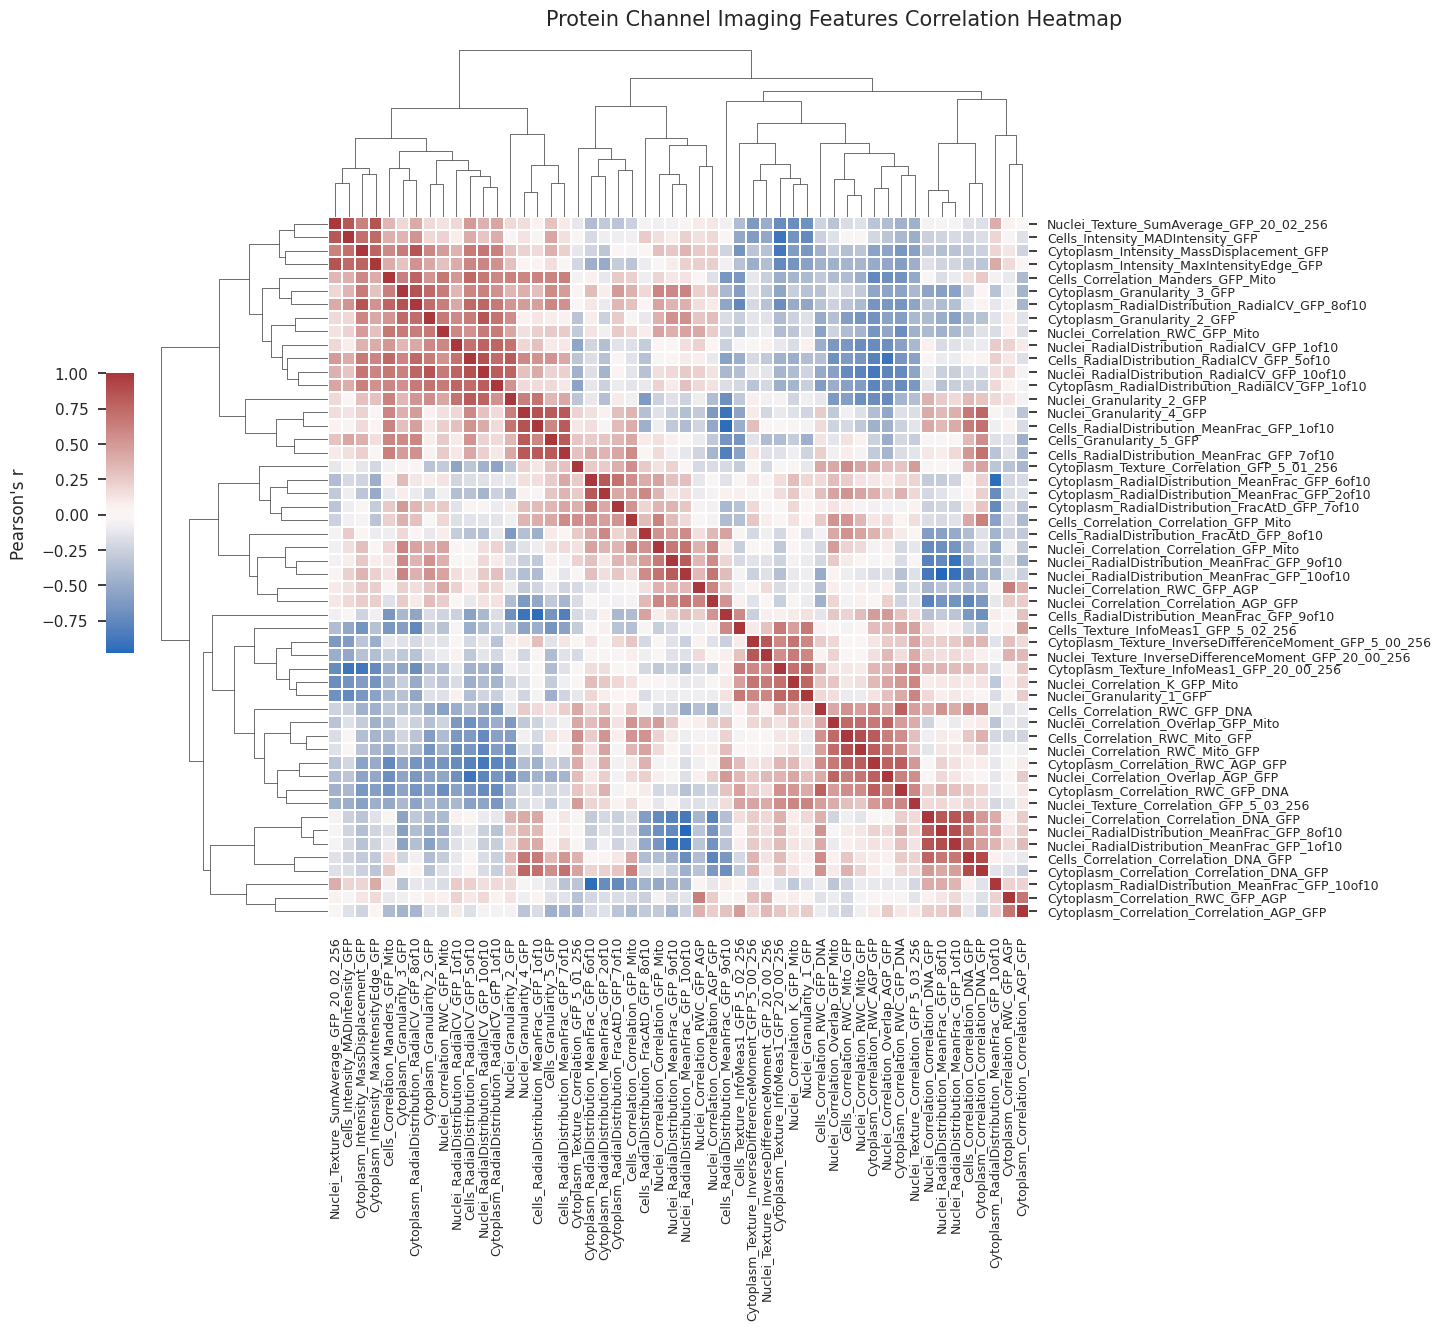

In [34]:
corr_df = df.loc[[idx for idx in row_colors_df.index if idx in pheno_alleles],:].corr()
g = sns.clustermap(
    data=corr_df,
    cmap="vlag",
    cbar_pos=(-.02, 0.55, 0.02, 0.2),
    yticklabels=1, xticklabels=1,
    square=True,
    figsize=(14,14),
    # annot=True, fmt=".2f",
    linewidth=.05, 
    # ax=ax
)
g.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g.cax.yaxis.set_label_position('left')
g.cax.yaxis.set_ticks_position('left')
g.cax.set_ylabel(r"Pearson's r", labelpad=10) ##pearman's $\rho$
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=9)
plt.show()

col_order = list(corr_df.columns[g.dendrogram_col.reordered_ind])

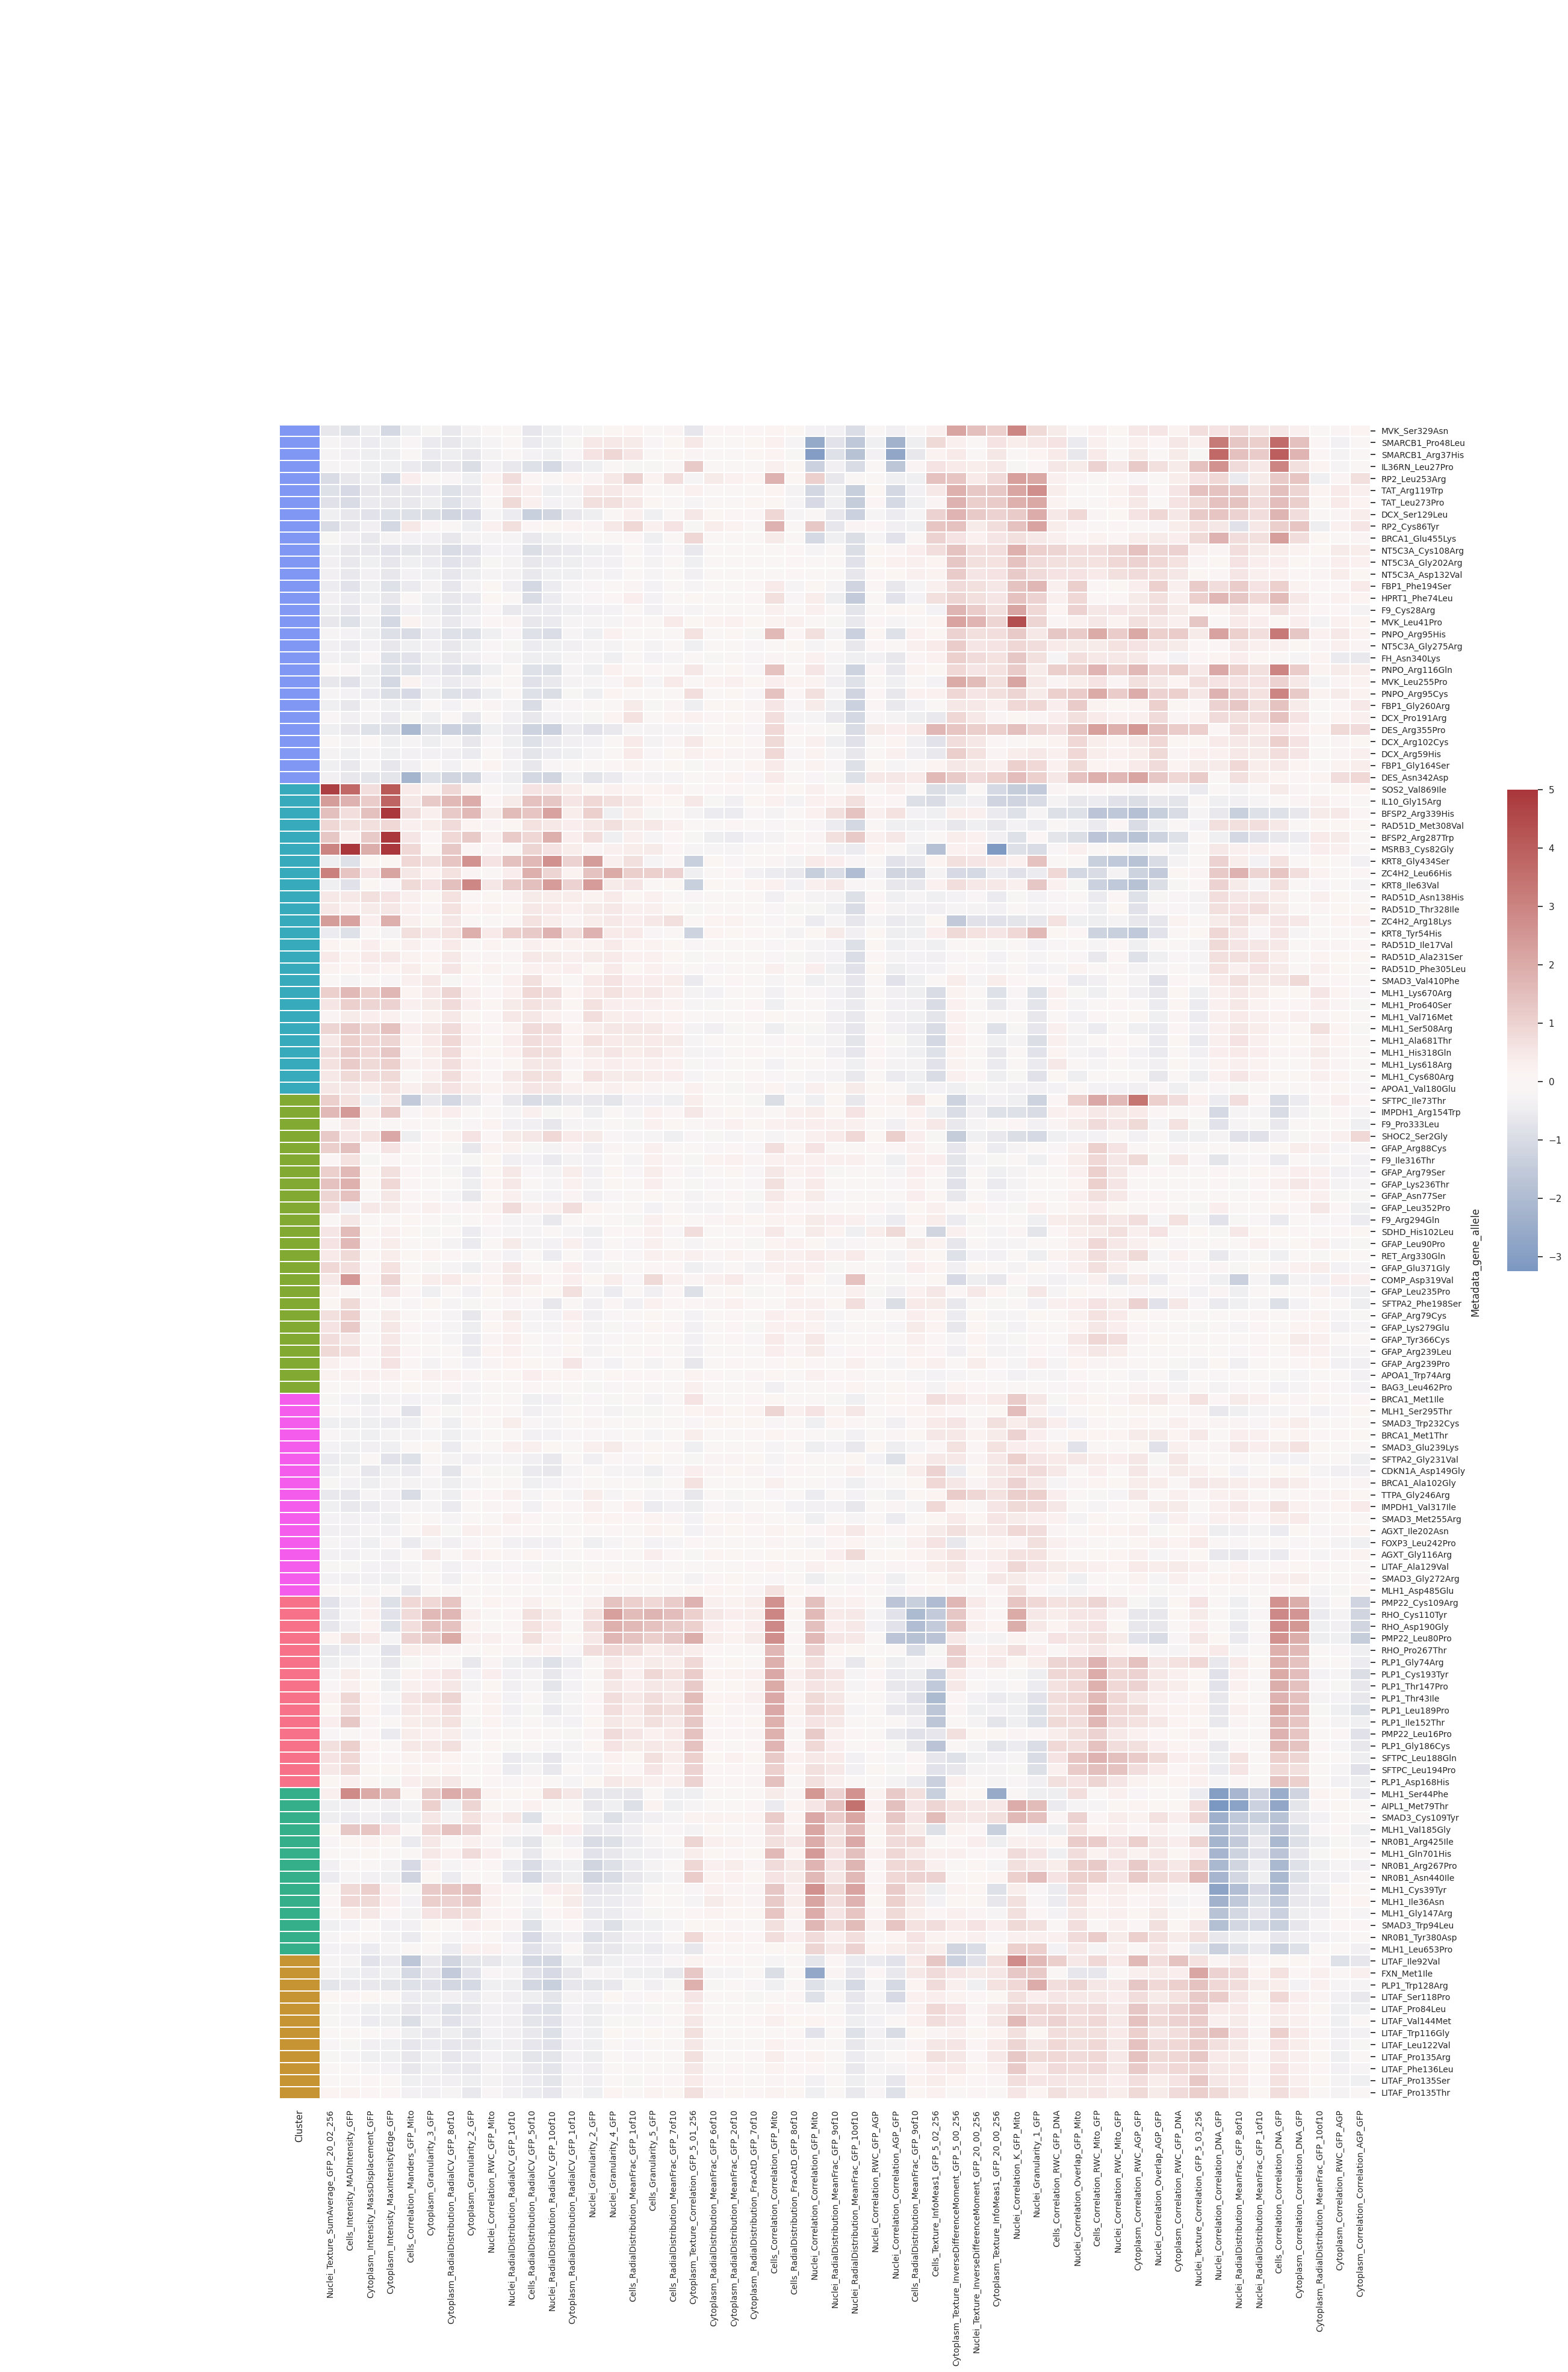

In [35]:
g = sns.clustermap(
    data=df.loc[[idx for idx in row_colors_df.index if idx in pheno_alleles],col_order],
    cmap="vlag",
    center=0,
    row_colors=row_colors_df.loc[[idx for idx in row_colors_df.index if idx in pheno_alleles],:],
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(1.005, 0.47, 0.02, 0.2),
    figsize=(25, 40),
    yticklabels=1, 
    linewidth=.05, 
    # xticklabels=1,
    # dendrogram_ratio=0
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

In [47]:
dr_res_df.to_csv("../../3_outputs/variant_clustering_results.csv")
corr_df.loc[col_order, col_order].to_csv("../../3_outputs/protein_features_corr_mat.csv")
df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order].to_csv("../../3_outputs/variant_protein_feature_matrix.csv")

## 3. Mislocalized Variants

In [13]:
misloc_var_sig_feat_df = feat_adj_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(misloc_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_misloc_alleles = misloc_var_sig_feat_df["cp_feature"].to_list()

In [36]:
norm_misloc_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_misloc_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_misloc_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_misloc_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_misloc_vars_feat_df = pl.concat(
        [norm_misloc_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 40/40 [00:08<00:00,  4.44it/s]


In [37]:
# Standardize the features before PCA
# var_zscore_feat_gfp_filtered_int_df = inverse_normal_transform(norm_vars_feat_df)
var_zscore_feat_gfp_filtered_int_df = norm_misloc_vars_feat_df.to_pandas().set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping)
# We clip values at -5 (lower) and +5 (upper)
var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(cols).rename(
        {k: f"Metadata_{k}" for k in cols if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

In [38]:
df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
display(df.head())

metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]
# ----------------------------------------------------------------------
# 2. Robust PCA
# ----------------------------------------------------------------------
# Dynamic component selection: Keep 90% of variance
pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)
n_pcs = data_pca.shape[1]
print(f"PCA retained {n_pcs} components explaining 90% variance.")

# Create PCA DataFrame dynamically
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]
pca_df = pd.DataFrame(data_pca, columns=pca_cols)
# Safely attach metadata using index alignment
pca_df = pd.concat([df_meta[metadata_cols].reset_index(drop=True), pca_df], axis=1)

# ----------------------------------------------------------------------
# 3. Robust Graph Construction (Euclidean + Higher K)
# ----------------------------------------------------------------------
k = 10  # Increased from 5 to 15 for better cluster stability
# CRITICAL CHANGE: Use 'euclidean' for PCA data, not 'cosine'
nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean")
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# ----------------------------------------------------------------------
# 4. UMAP (Aligned with Graph)
# ----------------------------------------------------------------------
umap_model = umap.UMAP(
    n_neighbors=k,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    metric="euclidean",  # Match the KNN metric
    init="spectral"      # More stable initialization
)

# Use precomputed KNN for consistency
umap_result = umap_model.fit_transform(data_pca, knn_indices=indices, knn_dists=distances)

umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])

# ----------------------------------------------------------------------
# 5. Leiden Clustering
# ----------------------------------------------------------------------
# Build graph from KNN indices
edges = []
# i is the sample index, neighbors are in indices[i]
for i in range(indices.shape[0]):
    # Note: indices[i, 0] is usually the point itself (distance 0), so we skip it
    for neighbor in indices[i, 1:]: 
        edges.append((i, neighbor))

g = ig.Graph(edges=edges, directed=False)

# Tune resolution: Start at 0.5 - 1.0. Lower = fewer, larger clusters.
resolution = 0.8 
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    weights=None, 
    resolution_parameter=resolution,
    seed=42
)
cluster_labels = np.array(partition.membership) + 1 # 1-based indexing

# ----------------------------------------------------------------------
# 6. Compile Results
# ----------------------------------------------------------------------
dr_res_df = pd.concat([pca_df, umap_df], axis=1)
dr_res_df["Metadata_cluster"] = cluster_labels
dr_res_df.index = df.index  # Preserve original index

# print("Clustering complete. Columns:", dr_res_df.columns)

,Cytoplasm_Granularity_2_GFP,Nuclei_Correlation_Overlap_GFP_Mito,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_GFP_DNA,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_Intensity_MassDisplacement_GFP,...,Cells_RadialDistribution_RadialCV_GFP_5of10,Cells_Correlation_Correlation_GFP_Mito,Nuclei_Granularity_1_GFP,Cells_Texture_InfoMeas1_GFP_5_02_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Intensity_MaxIntensityEdge_GFP,Cells_Correlation_RWC_GFP_AGP,Cells_Intensity_MADIntensity_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
PMP22_Leu16Pro,-0.235489,0.674763,1.388715,0.123601,0.299404,0.447052,0.070510,0.399950,-0.207805,0.023675,...,0.018661,1.874852,0.045008,-0.684502,0.118120,0.296230,-0.568252,0.088800,-0.151304,0.127735
FXN_Met1Ile,-0.762764,-0.695296,1.093524,0.339037,0.185791,-0.599746,-0.136045,-0.486585,-0.621225,-0.531649,...,-0.787900,-0.918532,1.221845,0.800369,0.423549,0.587348,-0.413455,-0.018309,-0.418047,0.553472
AGXT_Gly161Arg,0.316583,0.198685,-0.453538,0.152394,-0.177070,0.087289,0.082009,0.060823,-0.075724,-0.234657,...,-0.012132,0.220223,0.814237,0.598011,0.499272,0.871740,-0.237497,0.267222,-0.404441,0.532080
SFTPC_Ile73Thr,-0.636458,1.088555,0.401773,0.764809,0.633830,-0.453107,-0.147690,-0.433599,-0.584060,-0.430600,...,-0.963353,-0.900190,-1.260944,0.121551,-0.527963,-1.112744,0.493030,0.366453,0.639169,-0.361601
MLH1_Gln701His,0.797070,0.774611,0.375096,0.104474,-0.088785,-0.222774,0.137026,0.115792,0.065713,0.110980,...,-0.578963,1.674618,0.576428,0.305244,0.059967,0.325967,-0.129179,-0.009105,-0.087956,0.050365


PCA retained 8 components explaining 90% variance.


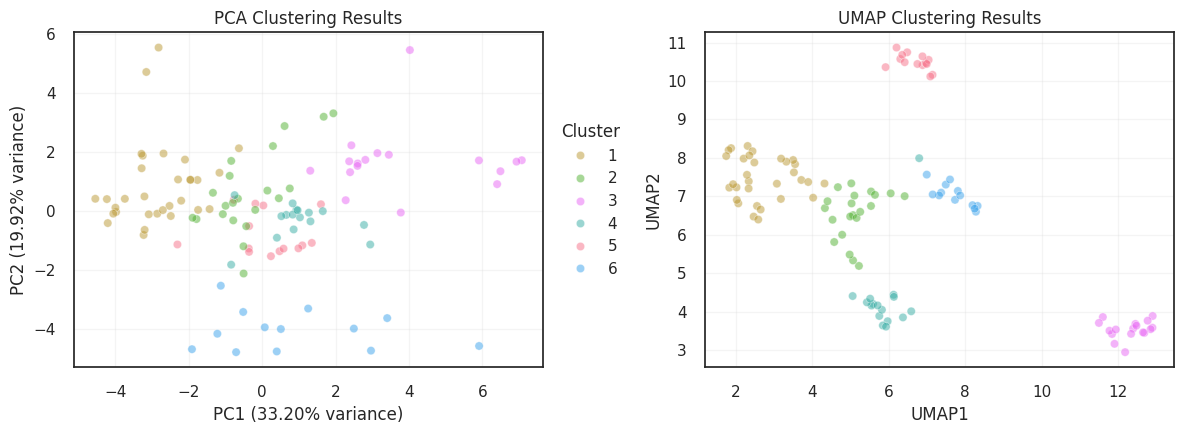

In [39]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=1)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5,
    legend=False
)
# Add text labels for high-scoring points in PCA
high_score_mask = dr_res_df['Metadata_img_pheno_hit']==True

# ax[1].get_legend().remove()

texts_pca = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_pca.append(
#       ax[0].text(
#        dr_res_df.loc[idx, 'PC1'],
#        dr_res_df.loc[idx, 'PC2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_pca, ax=ax[0], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# Add text labels for high-scoring points in UMAP
texts_umap = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_umap.append(ax[1].text(
#        dr_res_df.loc[idx, 'UMAP1'],
#        dr_res_df.loc[idx, 'UMAP2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_umap, ax=ax[1], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

In [41]:
# Get cluster order from UMAP clustering
cluster_order = dr_res_df.sort_values('Metadata_cluster')['Metadata_cluster'].unique()

# Create cluster color mapping
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
cluster_colors = sns.color_palette("husl", n_clusters)
cluster_color_map = {cluster: cluster_colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

# Create ordered list based on clusters, then by score within clusters
ordered_variants = []
cluster_labels = []

for cluster in cluster_order:
#    print(cluster)
   cluster_variants = dr_res_df[dr_res_df['Metadata_cluster']==cluster].sort_values('Metadata_img_misloc_score', ascending=False).index.tolist()
   ordered_variants.extend(cluster_variants)
#    print(len(ordered_variants))
   cluster_labels.extend([cluster] * len(cluster_variants))

available_variants = []
available_cluster_labels = []
for i, variant in enumerate(ordered_variants):
   if variant in dr_res_df.sort_values('Metadata_img_misloc_score').index:
       available_variants.append(variant)
       available_cluster_labels.append(cluster_labels[i])

## Combine both color arrays as separate columns
row_colors_df = pd.DataFrame(index=ordered_variants)
row_colors_df['Cluster'] = [cluster_color_map[cluster] for cluster in available_cluster_labels]
# row_colors_df['AUROC_GFP'] = list(auroc_colors)

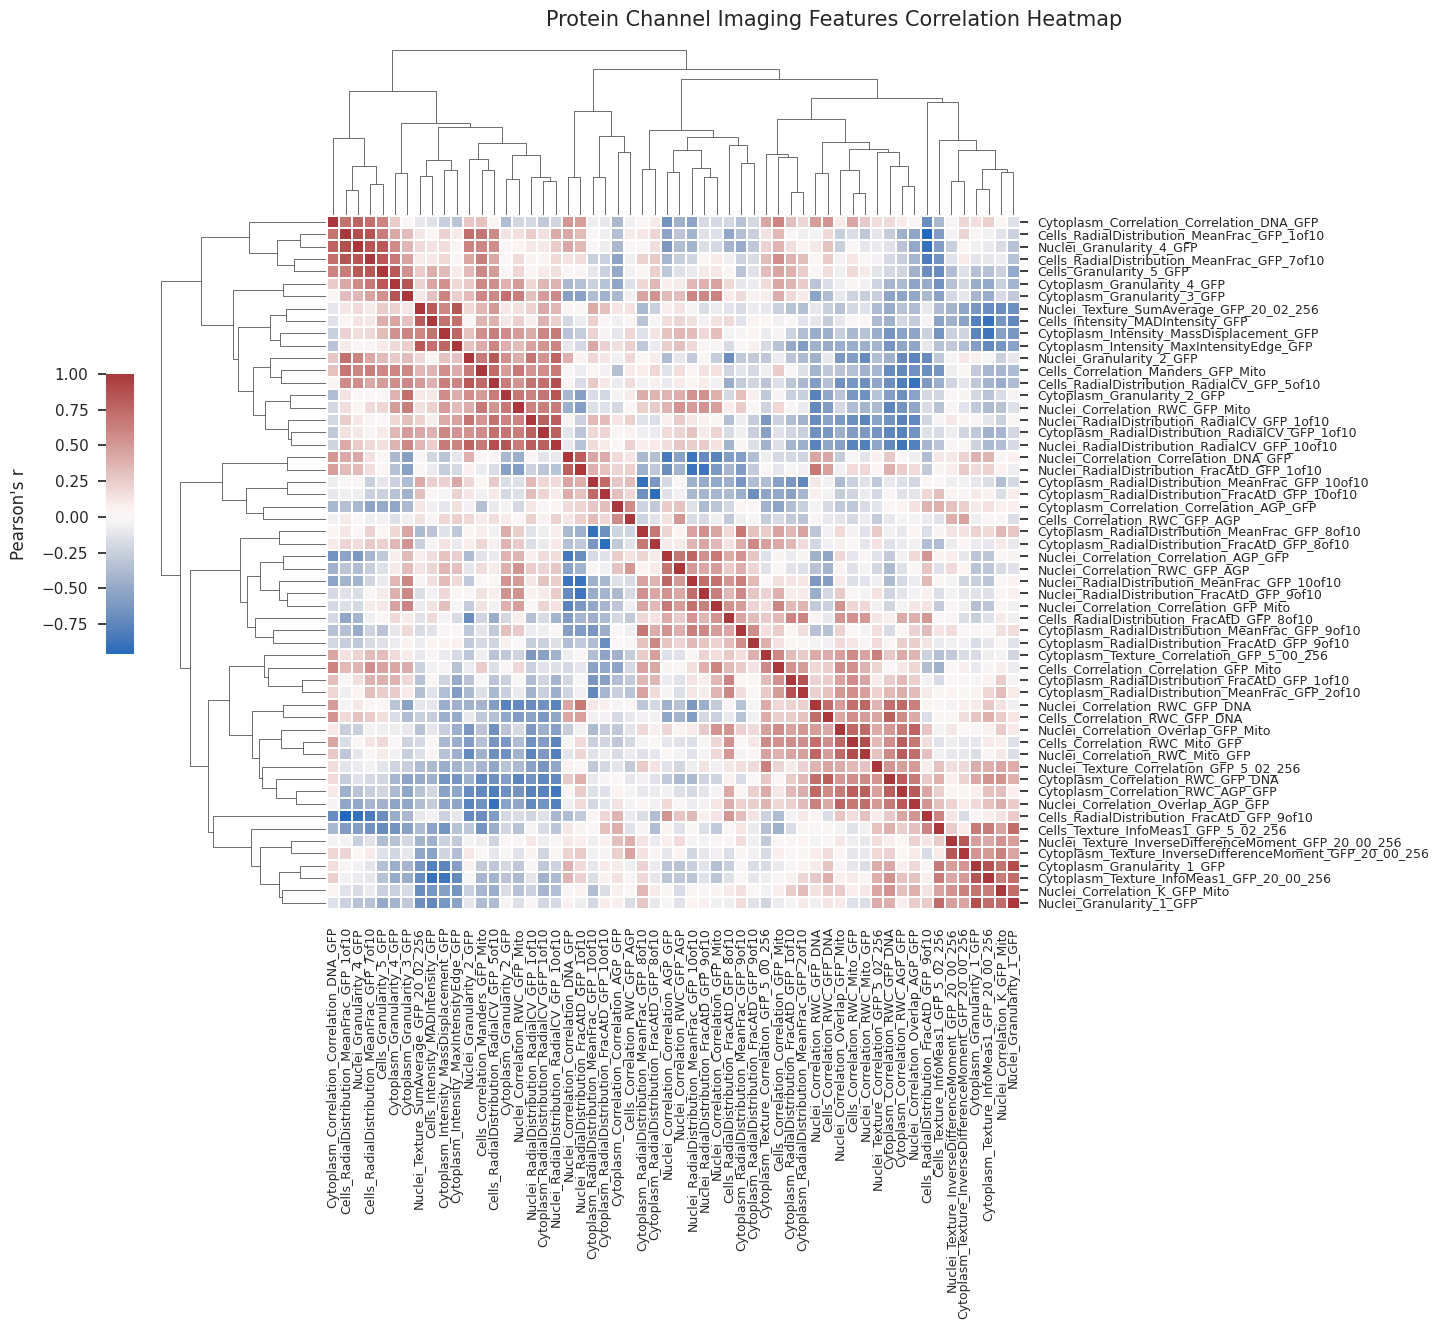

In [43]:
corr_df = df.loc[[idx for idx in row_colors_df.index if idx in pheno_alleles],:].corr()
g = sns.clustermap(
    data=corr_df,
    cmap="vlag",
    cbar_pos=(-.02, 0.55, 0.02, 0.2),
    yticklabels=1, xticklabels=1,
    square=True,
    figsize=(14,14),
    # annot=True, fmt=".2f",
    linewidth=.05, 
    # ax=ax
)
g.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g.cax.yaxis.set_label_position('left')
g.cax.yaxis.set_ticks_position('left')
g.cax.set_ylabel(r"Pearson's r", labelpad=10) ##pearman's $\rho$
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=9)
plt.show()

col_order = list(corr_df.columns[g.dendrogram_col.reordered_ind])

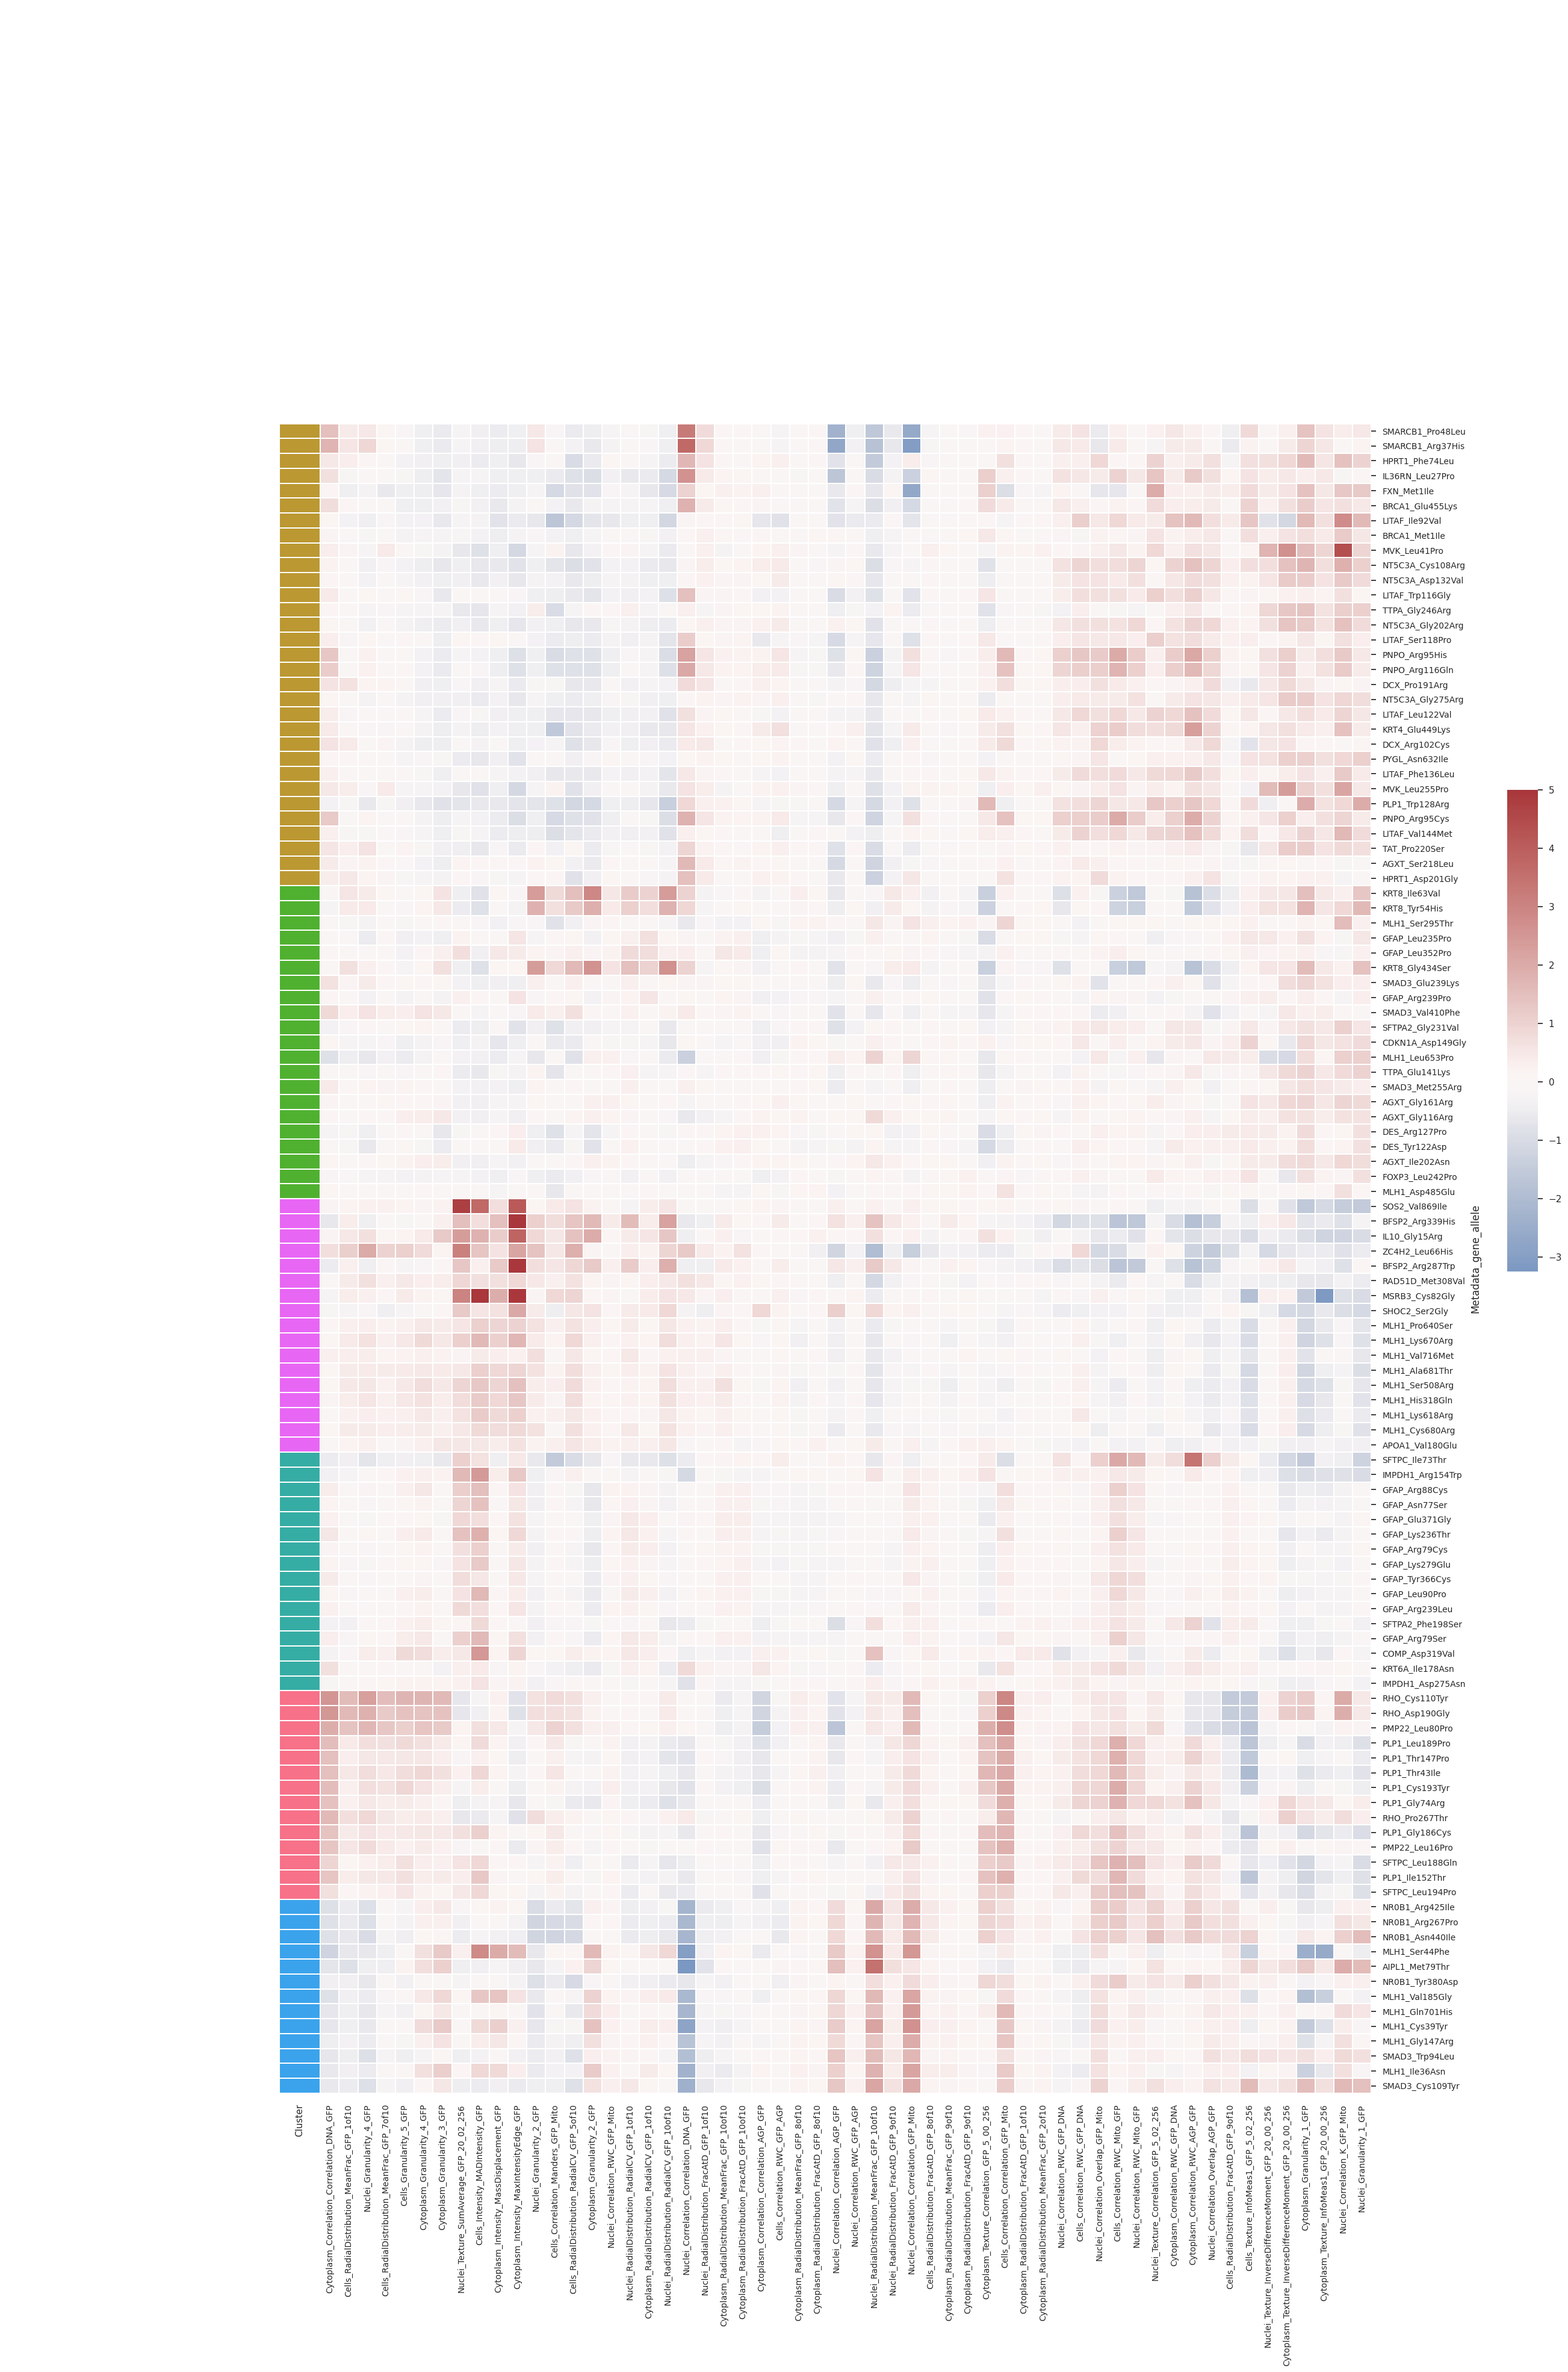

In [44]:
g = sns.clustermap(
    data=df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order],
    cmap="vlag",
    center=0,
    row_colors=row_colors_df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],:],
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(1.005, 0.47, 0.02, 0.2),
    figsize=(25, 40),
    yticklabels=1, 
    linewidth=.05, 
    # xticklabels=1,
    # dendrogram_ratio=0
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()